In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import joblib

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

from scipy.sparse import save_npz, load_npz

print("All required libraries imported successfully!")

All required libraries imported successfully!


In [2]:
import os

print(os.listdir('/content'))

['.config', '.ipynb_checkpoints', 'TED_Talks_EDA_Prepared.csv', 'sample_data']


In [3]:
df = pd.read_csv('/content/TED_Talks_EDA_Prepared.csv')

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

Dataset loaded successfully!
Dataset shape: (4016, 25)


In [4]:
print("Dataset dimensions:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five rows:")
display(df.head())

Dataset dimensions: (4016, 25)

Column names:
['Talk_Id', 'Title', 'Speaker_1', 'All_Speakers', 'Occupations', 'About_speakers', 'Views', 'Recorded_date', 'Published_date', 'Event', 'Native_lang', 'Available_lang', 'Comments', 'Duration', 'Topics', 'Related_talks', 'URL', 'Description', 'Transcript', 'Topic_Count', 'Title_Word_Count', 'Description_Word_Count', 'Transcript_Word_Count', 'About_speakers_Word_Count', 'Combined_Text']

First five rows:


,Talk_Id,Title,Speaker_1,All_Speakers,Occupations,About_speakers,Views,Recorded_date,Published_date,Event,...,Related_talks,URL,Description,Transcript,Topic_Count,Title_Word_Count,Description_Word_Count,Transcript_Word_Count,About_speakers_Word_Count,Combined_Text
0,1,Averting the climate crisis,Al Gore,{0: 'Al Gore'},{0: ['climate advocate']},{0: 'Nobel Laureate Al Gore focused the world’...,3523392.0,25-02-2006,27-06-2006,TED2006,...,"{243: 'New thinking on the climate crisis', 54...",https://www.ted.com/talks/al_gore_averting_the...,With the same humor and humanity he exuded in ...,"Thank you so much, Chris. And it's truly a gre...",9,4,39,2153,24,Averting the climate crisis ['alternative ener...
1,92,The best stats you've ever seen,Hans Rosling,{0: 'Hans Rosling'},{0: ['global health expert; data visionary']},"{0: 'In Hans Rosling’s hands, data sings. Glob...",14501685.0,22-02-2006,27-06-2006,TED2006,...,"{2056: ""Own your body's data"", 2296: 'A visual...",https://www.ted.com/talks/hans_rosling_the_bes...,You've never seen data presented like this. Wi...,"About 10 years ago, I took on the task to teac...",11,6,26,3174,35,"The best stats you've ever seen ['Africa', 'As..."
2,7,Simplicity sells,David Pogue,{0: 'David Pogue'},{0: ['technology columnist']},{0: 'David Pogue is the personal technology co...,1920832.0,24-02-2006,27-06-2006,TED2006,...,"{1725: '10 top time-saving tech tips', 2274: '...",https://www.ted.com/talks/david_pogue_simplici...,New York Times columnist David Pogue takes aim...,"(Music: ""The Sound of Silence,"" Simon & Garfun...",9,2,31,3371,45,"Simplicity sells ['computers', 'entertainment'..."
3,53,Greening the ghetto,Majora Carter,{0: 'Majora Carter'},{0: ['activist for environmental justice']},{0: 'Majora Carter redefined the field of envi...,2664069.0,26-02-2006,27-06-2006,TED2006,...,{1041: '3 stories of local eco-entrepreneurshi...,https://www.ted.com/talks/majora_carter_greeni...,"In an emotionally charged talk, MacArthur-winn...",If you're here today — and I'm very happy that...,9,3,31,3071,32,"Greening the ghetto ['MacArthur grant', 'activ..."
4,66,Do schools kill creativity?,Sir Ken Robinson,{0: 'Sir Ken Robinson'},"{0: ['author', 'educator']}","{0: ""Creativity expert Sir Ken Robinson challe...",65051954.0,25-02-2006,27-06-2006,TED2006,...,"{865: 'Bring on the learning revolution!', 173...",https://www.ted.com/talks/sir_ken_robinson_do_...,Sir Ken Robinson makes an entertaining and pro...,Good morning. How are you? (Audience) Good. It...,7,4,21,3170,32,"Do schools kill creativity? ['children', 'crea..."


**Check the required columns :**
---

In [5]:
required_columns = ['Title', 'Topics', 'Transcript']

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    print("Missing columns:", missing_columns)
else:
    print("All required columns are available!")
    display(df[required_columns].head())

All required columns are available!


,Title,Topics,Transcript
0,Averting the climate crisis,"['alternative energy', 'cars', 'climate change...","Thank you so much, Chris. And it's truly a gre..."
1,The best stats you've ever seen,"['Africa', 'Asia', 'Google', 'demo', 'economic...","About 10 years ago, I took on the task to teac..."
2,Simplicity sells,"['computers', 'entertainment', 'interface desi...","(Music: ""The Sound of Silence,"" Simon & Garfun..."
3,Greening the ghetto,"['MacArthur grant', 'activism', 'business', 'c...",If you're here today — and I'm very happy that...
4,Do schools kill creativity?,"['children', 'creativity', 'culture', 'dance',...",Good morning. How are you? (Audience) Good. It...


**Check missing values in the required columns :**
---



***Before vectorization***, we need to understand whether any required text fields contain missing values.

In [6]:
print("Missing values in required columns:\n")

print(df[required_columns].isnull().sum())

Missing values in required columns:

Title         0
Topics        0
Transcript    0
dtype: int64


**Handle missing values and prepare the text**
---



In [8]:
# Create a working copy
df = df.copy()

# Fill missing text values
for col in required_columns:
    df[col] = df[col].fillna('').astype(str)

# Remove leading and trailing spaces
for col in required_columns:
    df[col] = df[col].str.strip()

# Combine title, topics, and transcript
df['Combined_Text'] = (
    df['Title'] + ' ' +
    df['Topics'] + ' ' +
    df['Transcript']
).str.strip()

print("Text preparation completed!")

display(
    df[['Title', 'Topics', 'Combined_Text']].head()
)

Text preparation completed!


,Title,Topics,Combined_Text
0,Averting the climate crisis,"['alternative energy', 'cars', 'climate change...",Averting the climate crisis ['alternative ener...
1,The best stats you've ever seen,"['Africa', 'Asia', 'Google', 'demo', 'economic...","The best stats you've ever seen ['Africa', 'As..."
2,Simplicity sells,"['computers', 'entertainment', 'interface desi...","Simplicity sells ['computers', 'entertainment'..."
3,Greening the ghetto,"['MacArthur grant', 'activism', 'business', 'c...","Greening the ghetto ['MacArthur grant', 'activ..."
4,Do schools kill creativity?,"['children', 'creativity', 'culture', 'dance',...","Do schools kill creativity? ['children', 'crea..."


**Check Empty Text Records :**
---



In [9]:
empty_text_count = df['Combined_Text'].eq('').sum()

print("Total TED Talks:", len(df))
print("Empty combined-text records:", empty_text_count)
print(
    "Non-empty combined-text records:",
    len(df) - empty_text_count
)

Total TED Talks: 4016
Empty combined-text records: 0
Non-empty combined-text records: 4016


In [10]:
df_model = df.loc[
    df['Combined_Text'].ne('')
].copy()

# Reset the index so that row positions align with matrix positions
df_model.reset_index(drop=True, inplace=True)

print("Original dataset shape:", df.shape)
print("Modeling dataset shape:", df_model.shape)

Original dataset shape: (4016, 25)
Modeling dataset shape: (4016, 25)


**Create the TF-IDF vectorizer :**
---



In [11]:
tfidf_vectorizer = TfidfVectorizer(
    stop_words='english',
    max_features=10000,
    min_df=2,
    max_df=0.95,
    ngram_range=(1, 2),
    dtype=np.float32
)

print("TF-IDF vectorizer created successfully!")

TF-IDF vectorizer created successfully!


**Convert text into numerical vectors :**
---



In [12]:
tfidf_matrix = tfidf_vectorizer.fit_transform(
    df_model['Combined_Text']
)

print("TF-IDF vectorization completed!")

print("Number of talks:", tfidf_matrix.shape[0])
print("Number of features:", tfidf_matrix.shape[1])

print("Matrix shape:", tfidf_matrix.shape)
print("Number of non-zero values:", tfidf_matrix.nnz)

print("Matrix type:", type(tfidf_matrix))

TF-IDF vectorization completed!
Number of talks: 4016
Number of features: 10000
Matrix shape: (4016, 10000)
Number of non-zero values: 1650578
Matrix type: <class 'scipy.sparse._csr.csr_matrix'>


In [13]:
feature_names = tfidf_vectorizer.get_feature_names_out()

print("Total vocabulary features:", len(feature_names))

print("\nFirst 30 features:")
print(feature_names[:30])

Total vocabulary features: 10000

First 30 features:
['000' '000 children' '000 dollars' '000 feet' '000 miles' '000 people'
 '000 times' '000 year' '000 years' '10' '10 000' '10 15' '10 20'
 '10 billion' '10 million' '10 minutes' '10 percent' '10 times' '10 year'
 '10 years' '100' '100 000' '100 billion' '100 million' '100 percent'
 '100 times' '100 years' '11' '11 years' '11th']


**Apply TF-IDF to topics :**
---



In [14]:
topics_vectorizer = TfidfVectorizer(
    lowercase=True,
    stop_words='english',
    token_pattern=r'(?u)\b\w+\b',
    dtype=np.float32
)

topics_matrix = topics_vectorizer.fit_transform(
    df_model['Topics']
)

print("Topic vectorization completed!")

print("Topics matrix shape:", topics_matrix.shape)
print("Number of topic features:", topics_matrix.shape[1])
print("Number of non-zero values:", topics_matrix.nnz)

Topic vectorization completed!
Topics matrix shape: (4016, 535)
Number of topic features: 535
Number of non-zero values: 35998


**Why do we need two representations?**
---



| Representation       | Text used                   | Purpose                                  |
| -------------------- | --------------------------- | ---------------------------------------- |
| Combined-text TF-IDF | Title + Topics + Transcript | Finds talks with similar overall content |
| Topics TF-IDF        | Topics only                 | Finds talks with similar topic labels    |


**Calculate cosine similarity :**
---
 Here, We use ***Sparse Matrix Multiplication***


In [15]:
similarity_matrix = cosine_similarity(
    tfidf_matrix,
    dense_output=False
)

print("Cosine similarity calculation completed!")

print("Similarity matrix shape:", similarity_matrix.shape)

print("Number of stored similarity values:",
      similarity_matrix.nnz)

print("Similarity matrix type:",
      type(similarity_matrix))

Cosine similarity calculation completed!
Similarity matrix shape: (4016, 4016)
Number of stored similarity values: 16105958
Similarity matrix type: <class 'scipy.sparse._csr.csr_matrix'>


First 5 Similarity Matrix :
---



In [16]:
sample_size = min(5, len(df_model))

sample_similarity = similarity_matrix[
    :sample_size, :sample_size
].toarray()

sample_titles = df_model['Title'].iloc[:sample_size]

sample_similarity_df = pd.DataFrame(
    sample_similarity,
    index=sample_titles,
    columns=sample_titles
)

display(sample_similarity_df.round(3))

Title,Averting the climate crisis,The best stats you've ever seen,Simplicity sells,Greening the ghetto,Do schools kill creativity?
Title,,,,,
Averting the climate crisis,1.000,0.128,0.218,0.154,0.206
The best stats you've ever seen,0.128,1.000,0.136,0.135,0.117
Simplicity sells,0.218,0.136,1.000,0.129,0.229
Greening the ghetto,0.154,0.135,0.129,1.000,0.119
Do schools kill creativity?,0.206,0.117,0.229,0.119,1.000


**Create a recommendation function**
---

---





**1. Recommend similar talks :**
---



In [17]:
def recommend_talks(title, top_n=5):

    # Find the selected talk
    matches = df_model.index[
        df_model['Title'].str.casefold()
        == title.strip().casefold()
    ].tolist()

    if not matches:
        print("Talk title not found in the dataset.")
        return None

    talk_idx = matches[0]

    # Retrieve its similarity scores
    scores = similarity_matrix.getrow(
        talk_idx
    ).toarray().ravel()

    # Exclude the selected talk
    scores[talk_idx] = -1

    # Get the most similar talks
    top_indices = np.argsort(scores)[::-1][:top_n]

    recommendations = df_model.iloc[
        top_indices
    ][['Title', 'Speaker_1', 'Topics']].copy()

    recommendations['Similarity_Score'] = scores[
        top_indices
    ]

    return recommendations.reset_index(drop=True)

**2. Test the recommendation function :**
---



In [18]:
selected_title = df_model['Title'].iloc[0]

print("Selected TED Talk:")
print(selected_title)

print("\nRecommended TED Talks:")

display(
    recommend_talks(
        selected_title,
        top_n=5
    )
)

Selected TED Talk:
Averting the climate crisis

Recommended TED Talks:


,Title,Speaker_1,Topics,Similarity_Score
0,New thinking on the climate crisis,Al Gore,"['activism', 'climate change', 'global issues'...",0.335722
1,A climate solution where all sides can win,Ted Halstead,"['big problems', 'business', 'china', 'economi...",0.299987
2,How we can turn the tide on climate,Chris Anderson,"['climate change', 'environment', 'activism', ...",0.293013
3,A one-man world summit,Rory Bremner,"['comedy', 'global issues', 'government', 'per...",0.288159
4,The case for optimism on climate change,Al Gore,"['climate change', 'weather', 'science', 'alte...",0.284846


**Identify important TF-IDF features :**
---



In [19]:
talk_idx = 0

# Get the selected talk's vector
talk_vector = tfidf_matrix.getrow(talk_idx)

# Get the vocabulary
feature_names = tfidf_vectorizer.get_feature_names_out()

# Extract non-zero feature indices and scores
feature_indices = talk_vector.indices
feature_scores = talk_vector.data

# Create a DataFrame
feature_importance = pd.DataFrame({
    'Feature': feature_names[feature_indices],
    'TF_IDF_Score': feature_scores
})

# Sort features by score
feature_importance = feature_importance.sort_values(
    by='TF_IDF_Score',
    ascending=False
)

print("Selected talk:")
print(df_model.loc[talk_idx, 'Title'])

print("\nTop 15 TF-IDF features:")

display(feature_importance.head(15))

Selected talk:
Averting the climate crisis

Top 15 TF-IDF features:


,Feature,TF_IDF_Score
281,carbon,0.226506
34,laughter,0.221749
493,climate crisis,0.164781
295,emissions,0.152575
0,climate,0.152359
87,restaurant,0.147361
251,trucks,0.132977
538,global warming,0.124762
236,efficiency,0.123604
108,al,0.121008


**Visualize important features :**
---



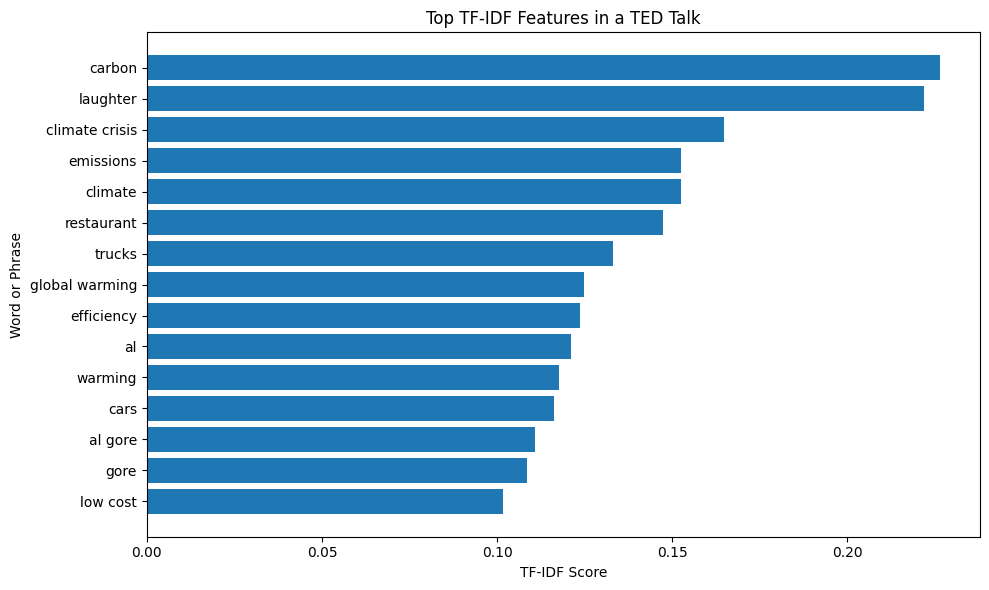

In [20]:
top_features = feature_importance.head(15).sort_values(
    by='TF_IDF_Score'
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features['Feature'],
    top_features['TF_IDF_Score']
)

plt.xlabel('TF-IDF Score')
plt.ylabel('Word or Phrase')

plt.title('Top TF-IDF Features in a TED Talk')

plt.tight_layout()
plt.show()

**Visualize similarity scores :**
---
**Plot the top five similar talks....**


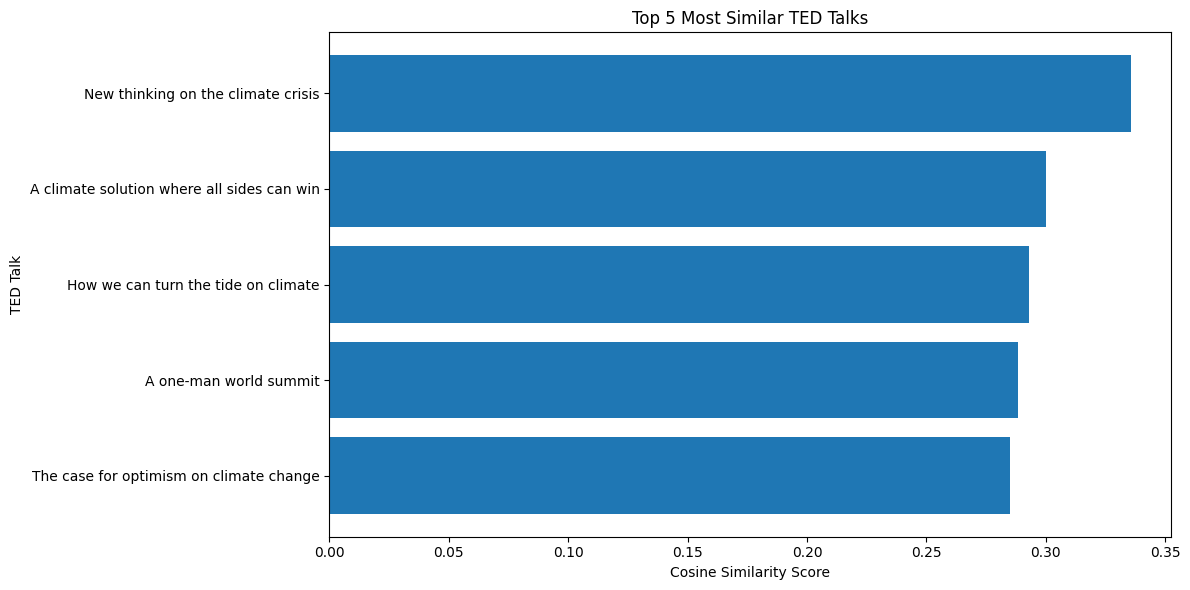

In [21]:
talk_idx = 0

scores = similarity_matrix.getrow(
    talk_idx
).toarray().ravel()

# Exclude the selected talk
scores[talk_idx] = -1

# Find the five most similar talks
top_indices = np.argsort(scores)[::-1][:5]

plot_data = pd.DataFrame({
    'Title': df_model.iloc[top_indices]['Title'].values,
    'Similarity_Score': scores[top_indices]
})

plot_data = plot_data.sort_values(
    by='Similarity_Score'
)

plt.figure(figsize=(12, 6))

plt.barh(
    plot_data['Title'],
    plot_data['Similarity_Score']
)

plt.xlabel('Cosine Similarity Score')
plt.ylabel('TED Talk')

plt.title('Top 5 Most Similar TED Talks')

plt.tight_layout()
plt.show()

**Saving Files :**
---



In [22]:
output_dir = '/content/milestone_3_outputs'

os.makedirs(output_dir, exist_ok=True)

print("Output directory created:", output_dir)

Output directory created: /content/milestone_3_outputs


In [23]:
joblib.dump(
    tfidf_vectorizer,
    f'{output_dir}/tfidf_vectorizer.pkl'
)

joblib.dump(
    topics_vectorizer,
    f'{output_dir}/topics_vectorizer.pkl'
)

print("Both fitted vectorizers saved successfully!")

Both fitted vectorizers saved successfully!


In [24]:
save_npz(
    f'{output_dir}/tfidf_matrix.npz',
    tfidf_matrix
)

save_npz(
    f'{output_dir}/topics_matrix.npz',
    topics_matrix
)

save_npz(
    f'{output_dir}/similarity_matrix.npz',
    similarity_matrix
)

print("All sparse matrices saved successfully!")

All sparse matrices saved successfully!


In [25]:
df_model.to_csv(
    f'{output_dir}/vectorized_dataset.csv',
    index=False
)

print("Modeling dataset saved successfully!")

Modeling dataset saved successfully!


In [34]:
documentation = """
MILESTONE 3: FEATURE ENGINEERING AND VECTORIZATION

Project: TED Talks Recommendation System

1. TEXT PREPARATION
   Combined the Title, Topics, and Transcript columns
   into a single Combined_Text feature.

2. COMBINED-TEXT VECTORIZATION
   Method: TF-IDF
   Stop words: English
   Maximum features: 10,000
   Minimum document frequency: 2
   Maximum document frequency: 0.95
   N-gram range: (1, 2)
   Data type: float32

3. TOPIC VECTORIZATION
   Method: TF-IDF
   Applied separately to the Topics column.
   Lowercase conversion: Enabled
   Stop words: English
   Data type: float32

4. SIMILARITY
   Method: Cosine similarity
   Input: Combined-text TF-IDF matrix
   Storage: Sparse matrix

5. INTERPRETABILITY
   Examined high-weight TF-IDF features and visualized
   similarity scores between TED Talks.

6. COLLABORATIVE FILTERING
   Requires user-item interaction data, such as ratings,
   likes, clicks, or viewing history.
   If this data is unavailable, collaborative filtering
   is not applicable to the current dataset.

7. OUTPUTS
   tfidf_vectorizer.pkl
   topics_vectorizer.pkl
   tfidf_matrix.npz
   topics_matrix.npz
   similarity_matrix.npz
   vectorized_dataset.csv
"""

with open(
    f'{output_dir}/milestone_3_documentation.txt',
    'w',
    encoding='utf-8'
) as file:
    file.write(documentation)

print("Milestone documentation saved successfully!")

Milestone documentation saved successfully!


In [35]:
print("Milestone 3 output files:\n")

for filename in sorted(os.listdir(output_dir)):
    filepath = os.path.join(output_dir, filename)

    size_kb = os.path.getsize(filepath) / 1024

    print(f"{filename} — {size_kb:.2f} KB")

Milestone 3 output files:

milestone_3_documentation.txt — 1.16 KB
similarity_matrix.npz — 74579.15 KB
tfidf_matrix.npz — 8445.14 KB
tfidf_vectorizer.pkl — 331.38 KB
topics_matrix.npz — 164.29 KB
topics_vectorizer.pkl — 9.56 KB
vectorized_dataset.csv — 84211.87 KB


In [36]:
import shutil

zip_path = shutil.make_archive(
    '/content/milestone_3_outputs',
    'zip',
    output_dir
)

print("ZIP file created:", zip_path)

ZIP file created: /content/milestone_3_outputs.zip


In [37]:
from google.colab import files

files.download(zip_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Testing :**
---

---





In [33]:
selected_title = df_model['Title'].iloc[5]

print("Selected Talk:")
print(selected_title)

print("\nRecommended Talks:")

display(
    recommend_talks(
        selected_title,
        top_n=5
    )
)

Selected Talk:
Behind the design of Seattle's library

Recommended Talks:


,Title,Speaker_1,Topics,Similarity_Score
0,Building a theater that remakes itself,Joshua Prince-Ramus,"['TEDx', 'architecture', 'creativity', 'design...",0.373351
1,My days as a young rebel,Frank Gehry,"['architecture', 'collaboration', 'design', 'g...",0.319409
2,"Great design is serious, not solemn",Paula Scher,"['art', 'design', 'entertainment', 'happiness'...",0.303165
3,Building uniqueness,Moshe Safdie,"['architecture', 'cities', 'collaboration', 'c...",0.293354
4,Why the buildings of the future will be shaped...,Marc Kushner,"['TED Books', 'architecture', 'design', 'socia...",0.289498
